# E0.2a — Bollinger Walk States (clean research notebook)

**Scope:** Bollinger-derived state representation only. No RSI, volume, sentiment, trading signals, or model fitting. Separate raw 5-minute input from analysis outputs.

**Causality:** all signals are stamped at the **close** of a completed candle. A state is first available when its confirmation candle closes. Higher timeframe states must not be used earlier than that timestamp.

**Initial rules (hypotheses, not tuned):** lower walk = price near lower band (%B ≤ 0.15) with lower band declining; upper walk symmetrical. Confirm after 3 consecutive qualifying candles; exit after 2 consecutive non-near closes. These are native-bar persistence counts and therefore represent different elapsed times across resolutions. Walks describe *band proximity*, **not** breakout success or trading edge.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import requests
import json
import time
%matplotlib widget

from walk_states import bollinger_from_5m, detect_walk_states

START = "2025-01-01"
END = "2026-01-01"
NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

Expected candles: 105984


## 1. Connect the existing data source

The old notebook is not included in this package, so its data-loading code cannot safely be copied. Execute the same trusted loader from `02_price_features.ipynb` **here**, assigning the result to `bars`. Required: 5-minute OHLCV with UTC candle-**open** datetime index and `open, high, low, close, volume` columns. Include sufficient history **before** START for 1D 20-day warm-up. Do **not** fabricate or forward-fill missing candles.

In [2]:
# TODO: paste ONLY your verified 5m data-loading cell here.

all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()


if 'bars' not in globals():
    raise RuntimeError("Load your actual 5-minute OHLCV dataframe as `bars` in this cell.")

assert isinstance(bars, pd.DataFrame)
assert {'open','high','low','close','volume'} <= set(bars.columns)
print('Source rows:',len(bars),'From:',bars.index.min(),'To:',bars.index.max())

Loaded 105,984 candles
Download/cache loading complete.
Source rows: 105984 From: 2024-12-30 00:00:00+00:00 To: 2026-01-01 23:55:00+00:00


## 2. Independent states for every timeframe

Compute all states from their **own** completed resampled candles. Each `runs[label]` keeps its own bands, states, transitions and settings.

In [5]:
runs = {}
for label, resolution in CONFIGS.items():
    bb = bollinger_from_5m(bars, START, END, resolution=resolution, window=WINDOW)
    states, transitions = detect_walk_states(
        bb, near=NEAR, confirm_bars=CONFIRM_BARS,
        exit_bars=EXIT_BARS, slope_bars=SLOPE_BARS,
    )
    runs[label] = dict(bb=bb, states=states, transitions=transitions, resolution=resolution)
    print(label, 'candles',len(bb),'transitions',len(transitions))

1D candles 368 transitions 26
1H candles 8832 transitions 655
15m candles 35328 transitions 2525
5m candles 105984 transitions 8139


## 3. Diagnostics (confirmed states only)

Duration is in actual hours. Percentages use valid band observations only. `NEUTRAL` includes both truly neutral behavior and *preconfirmation* intervals; missing data is excluded from prevalence.

In [6]:
summary_rows=[]
for label, run in runs.items():
    state=run['states']
    valid=state['pct_b'].notna()
    denominator=valid.sum()
    counts=state.loc[valid,'state'].value_counts()
    transitions=run['transitions']
    summary_rows.append(dict(
        resolution=label, valid_candles=int(denominator),
        lower_walk_pct=round(100*counts.get('LOWER_WALK',0)/denominator,2) if denominator else np.nan,
        upper_walk_pct=round(100*counts.get('UPPER_WALK',0)/denominator,2) if denominator else np.nan,
        lower_entries=int((transitions.to_state=='LOWER_WALK').sum()) if len(transitions) else 0,
        upper_entries=int((transitions.to_state=='UPPER_WALK').sum()) if len(transitions) else 0,
        distance_exits=int((transitions.reason=='DISTANCE_EXIT').sum()) if len(transitions) else 0,
    ))
display(pd.DataFrame(summary_rows).set_index('resolution'))

,valid_candles,lower_walk_pct,upper_walk_pct,lower_entries,upper_entries,distance_exits
resolution,,,,,,
1D,349,10.32,7.45,8,5,13
1H,8813,9.45,10.01,158,170,327
15m,35309,9.53,9.58,615,648,1262
5m,105965,9.95,9.51,2013,2057,4069


## 4. November 2025 visual sanity check

The shaded states begin only on the confirmation candle close. These plots are diagnostic, not evidence of predictive performance.

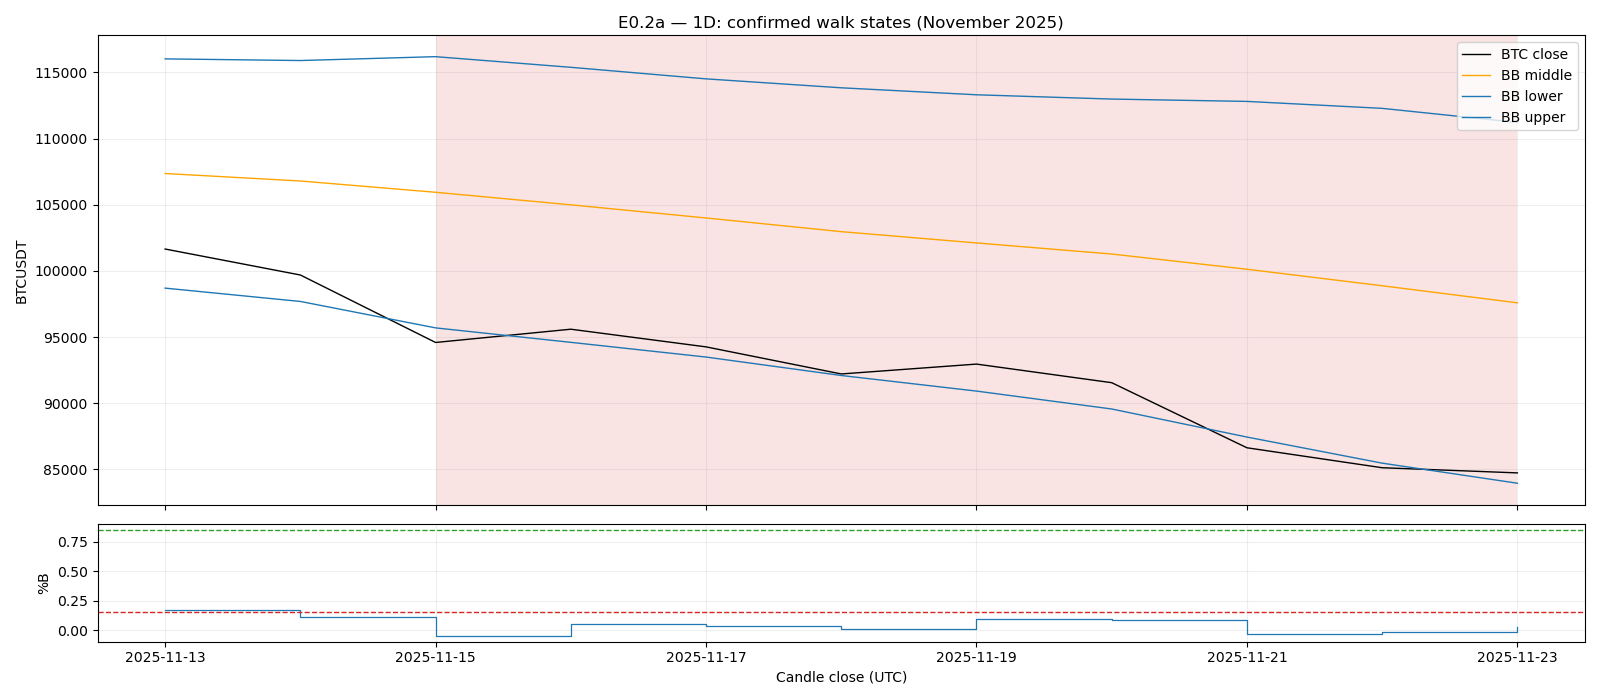

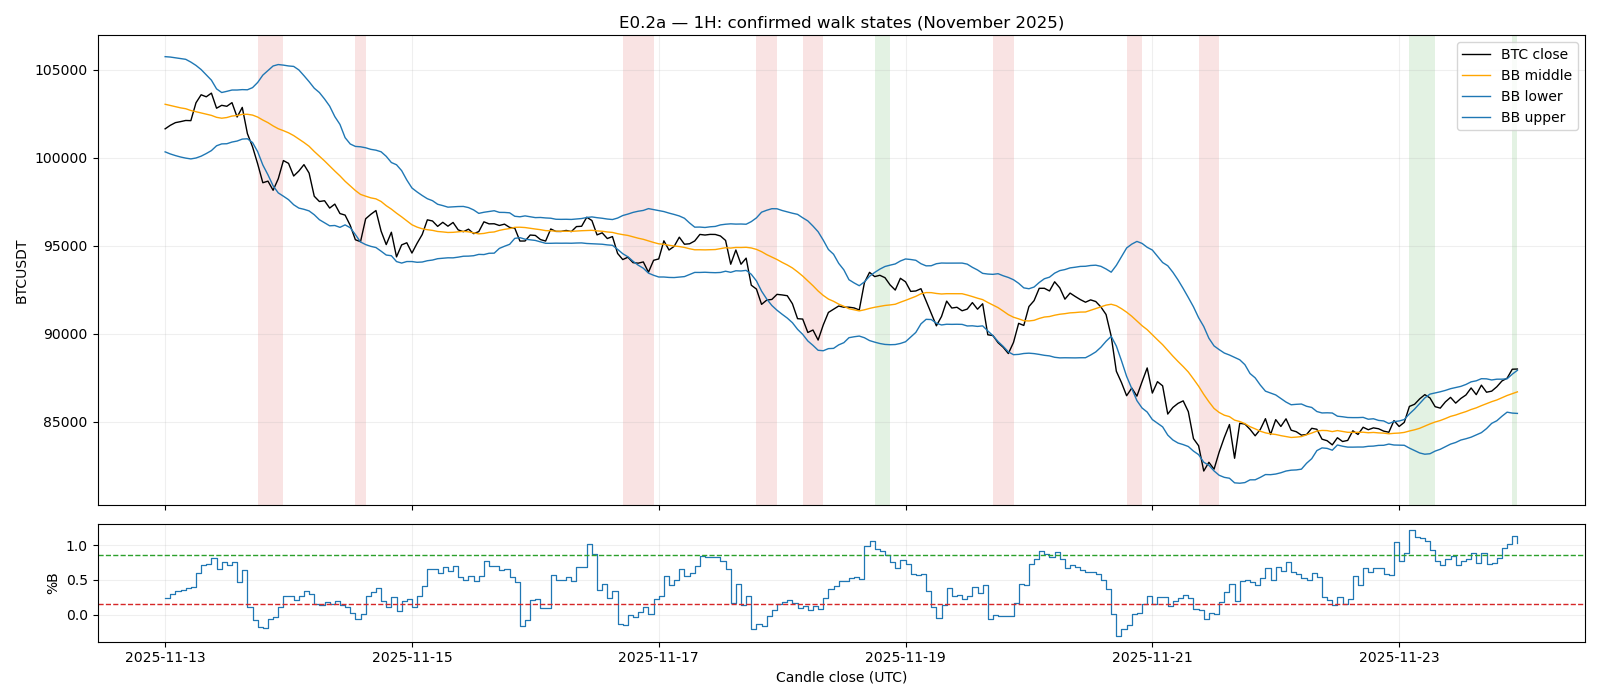

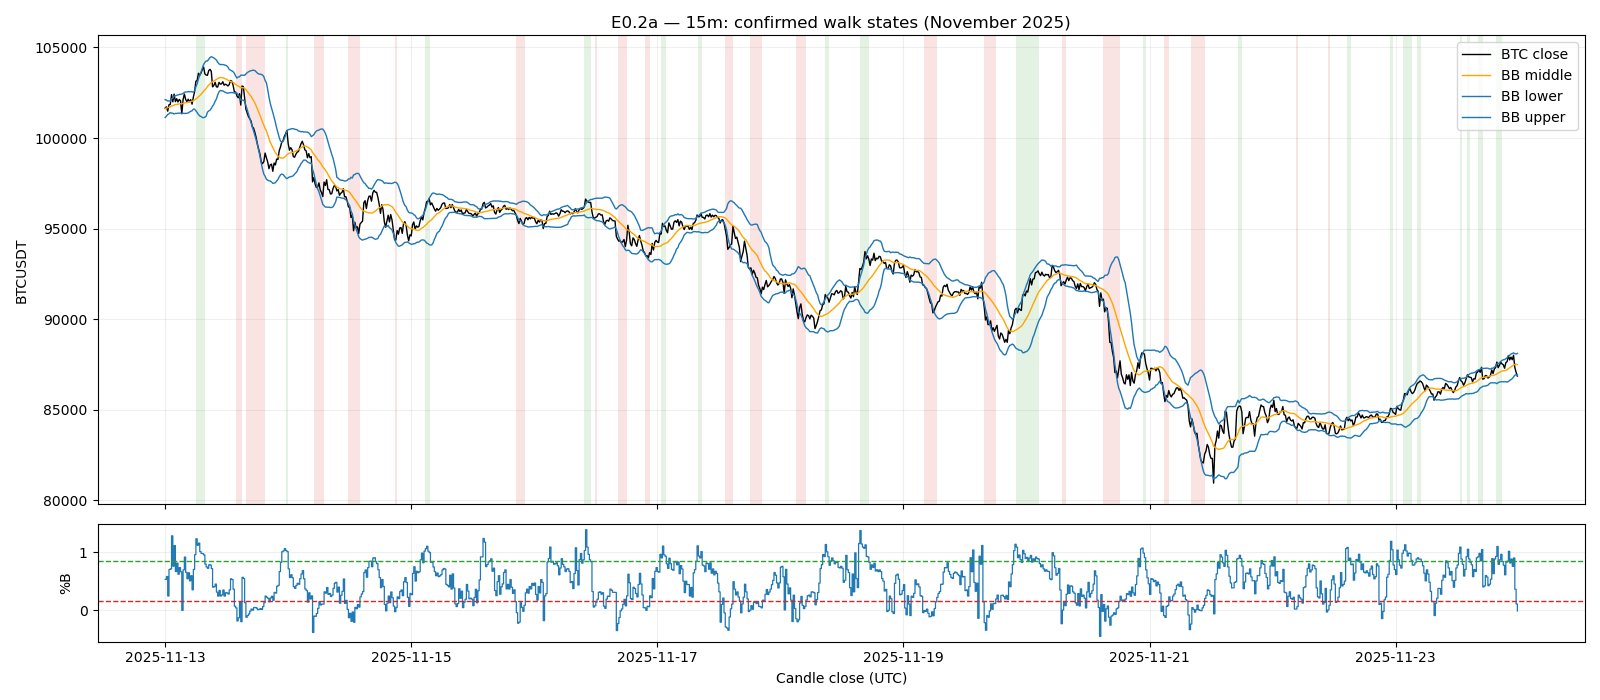

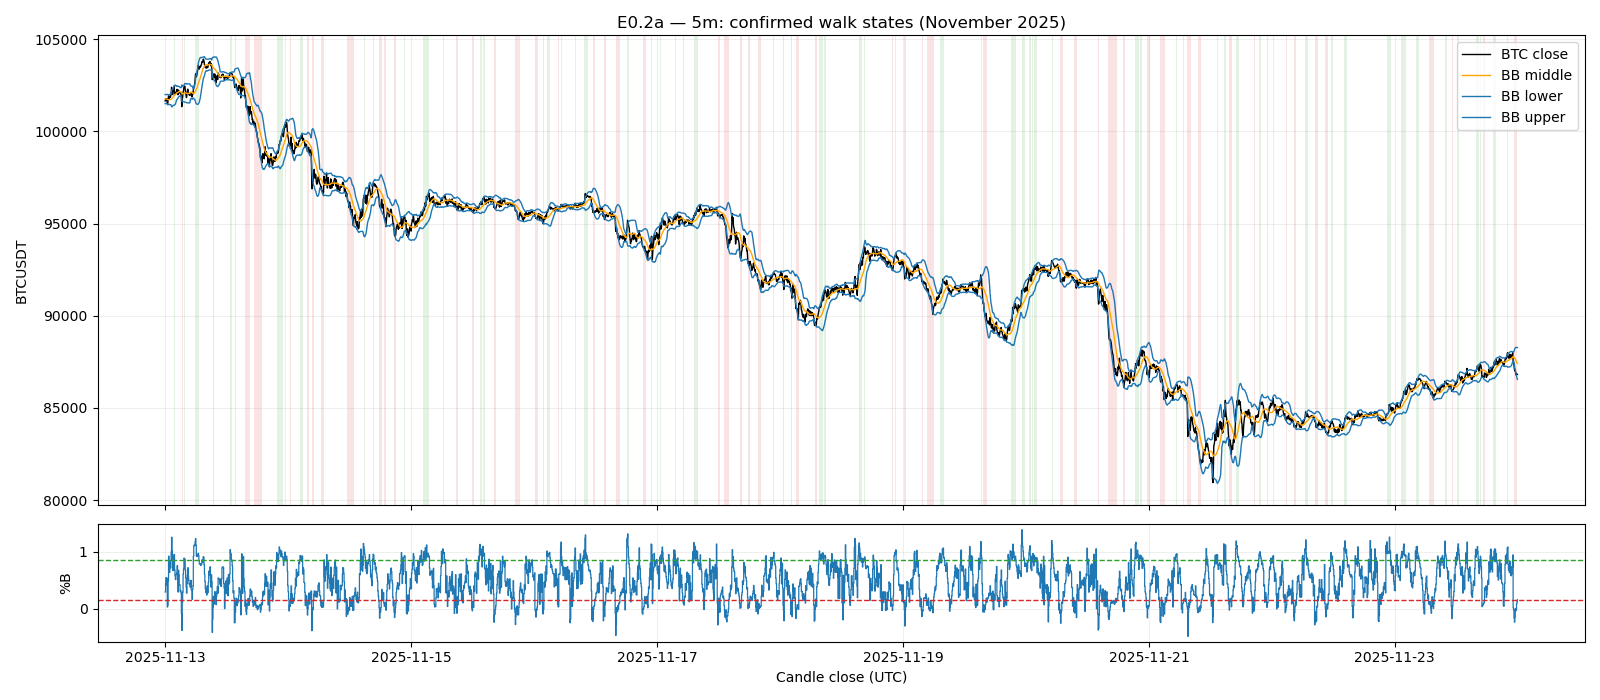

In [7]:
def plot_november(run, label, start=NOV_START, end=NOV_END):
    bb=run['bb'].loc[start:end]
    s=run['states'].loc[start:end]
    fig,(ax,ax2)=plt.subplots(2,1,figsize=(16,7),sharex=True,gridspec_kw={'height_ratios':[4,1]})
    ax.plot(bb.index,bb.close,color='black',lw=1,label='BTC close')
    ax.plot(bb.index,bb.bb_middle,color='orange',lw=1,label='BB middle')
    ax.plot(bb.index,bb.bb_lower,color='tab:blue',lw=1,label='BB lower')
    ax.plot(bb.index,bb.bb_upper,color='tab:blue',lw=1,label='BB upper')
    ax.legend(loc='upper right');ax.grid(alpha=.2)
    ax.set_ylabel('BTCUSDT')
    ax.set_title(f'E0.2a — {label}: confirmed walk states (November 2025)')
    color={'NEUTRAL':'gray','LOWER_WALK':'tab:red','UPPER_WALK':'tab:green'}
    dt=pd.Timedelta(run['resolution'])
    for t,st in s.state.items():
        if st!='NEUTRAL':
            ax.axvspan(t-dt,t,color=color[st],alpha=.13,lw=0)
    ax2.step(s.index,s.pct_b,where='post',lw=.9)
    ax2.axhline(NEAR,color='tab:red',ls='--',lw=1)
    ax2.axhline(1-NEAR,color='tab:green',ls='--',lw=1)
    ax2.set_ylabel('%B');ax2.grid(alpha=.2);ax2.set_xlabel('Candle close (UTC)')
    plt.tight_layout()
    return fig

%matplotlib widget
for label,run in runs.items():
    plot_november(run,label)
    plt.show()

## 5. Transition audit

A walk ending is **not** necessarily a reversal: the band can catch up during consolidation. Inspect confirmed transitions alongside BTC price before moving to forward-outcome labels.

In [15]:
for label,run in runs.items():
    transitions=run['transitions']
    mask=(transitions.time>=pd.Timestamp(NOV_START,tz='UTC')) & (transitions.time<pd.Timestamp(NOV_END,tz='UTC'))
    print('',label)
    display(transitions.loc[mask].head(30))

 1D


,time,from_state,to_state,reason
24,2025-11-16 00:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED


 1H


,time,from_state,to_state,reason
572,2025-11-13 19:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
573,2025-11-14 00:00:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
574,2025-11-14 14:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
575,2025-11-14 16:00:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
576,2025-11-16 18:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
577,2025-11-17 00:00:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
578,2025-11-17 20:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
579,2025-11-18 00:00:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
580,2025-11-18 05:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
581,2025-11-18 09:00:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT


 15m


,time,from_state,to_state,reason
2184,2025-11-13 06:15:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
2185,2025-11-13 08:00:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT
2186,2025-11-13 14:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
2187,2025-11-13 15:15:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
2188,2025-11-13 16:00:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
2189,2025-11-13 19:45:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
2190,2025-11-13 23:45:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
2191,2025-11-14 00:15:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT
2192,2025-11-14 05:15:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
2193,2025-11-14 07:15:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT


 5m


,time,from_state,to_state,reason
7090,2025-11-13 01:20:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
7091,2025-11-13 01:30:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT
7092,2025-11-13 01:45:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
7093,2025-11-13 01:55:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT
7094,2025-11-13 03:20:00+00:00,NEUTRAL,LOWER_WALK,CONFIRMED
7095,2025-11-13 03:30:00+00:00,LOWER_WALK,NEUTRAL,DISTANCE_EXIT
7096,2025-11-13 03:50:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
7097,2025-11-13 04:00:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT
7098,2025-11-13 05:50:00+00:00,NEUTRAL,UPPER_WALK,CONFIRMED
7099,2025-11-13 06:40:00+00:00,UPPER_WALK,NEUTRAL,DISTANCE_EXIT


## 6. Future E0.2b alignment (not yet a predictive model)

When combining states on the 5m decision timeline, use `merge_asof(..., direction="backward")` on completed candle-close timestamps, and confirm no missing-state forward-fill across data gaps. Do not retroactively label candidate candles as confirmed walks.

**Acceptance checks:** synthetic tests pass; November overlays are visually plausible; no state precedes confirmation; missing data resets the detector; no 1D current-day information leaks into earlier 5m observations. Next: examine sensitivity to proximity/confirmation parameters and map walk endings to causal forward outcomes.